# S14 · 稳健性、非平稳性与写作：把 14 天收成一个可投稿的方法章

> **Day 14 / 14** ｜ 对应论文章节 **3.10（Robustness） + 4.6（Discussion） + 5（Limitations）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 把前 13 天做过的**每一个方法决策**列成一张表，并知道每个决策可能怎样改变结论
- 识别**非平稳性**这个最隐蔽的偏差来源，并给出两种处理方案的对比
- 用暖年分层做一次类似 ENSO 的复合分析
- 用参数敏感性表判断：哪些结论稳、哪些结论只在特定设定下成立
- 拿到可直接改写的 Results / Discussion / Limitations 段落模板

---

## 1. 决策清单：你的论文到底做了多少个「选择」

一份 SCI 级方法章的价值，不在于写了多少公式，而在于**每一个自由度都被意识到并交代了**。

| # | 决策 | 本手册取值 | 换一个会怎样 |
|---|---|---|---|
| 1 | 基准期 | 1985–2014 | 改基准期 → 阈值整体平移 → 事件数变 |
| 2 | 阈值百分位 | 90 | 95 → 事件数骤降，尾部更极端 |
| 3 | 滑动窗半宽 | ±7 天 | ±14 → 阈值更平滑；±3 → 更贴近季节 |
| 4 | 最短持续 | 3 天 | 5 天 → 只剩强事件 |
| 5 | 合并间隔 | ≤2 天 | 0 → 事件被打碎，duration 变短 |
| 6 | 强度定义 | 峰值超出量 | 平均超出量 → 与时长更相关 |
| 7 | ARP 窗口 | 前 7 天 | 前 14 天 → 状态平滑，对比度下降 |
| 8 | 干/湿切点 | 30 / 50 | 20 / 40 → 分组更极端，样本更少 |
| 9 | 边缘分布 | 截断几何 + Gamma | Weibull/Lognormal → 尾部分位数变 |
| 10 | PIT 版本 | 中点（拟合）/ 随机化（诊断） | 只用随机化 → τ 被稀释 |
| 11 | copula 族 | ΔAIC<2 集成 | 只选最优 → 隐藏模型不确定性 |
| 12 | 重现期定义 | AND（另报 OR/Kendall） | 只报 OR → 重现期短 30–40% |
| 13 | 事件率分母 | 记录长度 44 年 | 有事件年份 34 年 → 低估风险 23% |
| 14 | 风险排序指标 | 年均 severity | 平均强度 → 排序与随机无异（S13） |

> 📌 这张表直接就是论文 **3.10 Sensitivity analyses** 的小节骨架。
> 不需要每个都做完整敏感性分析 —— 但要**说明每个选择**，并对其中影响最大的 3–4 个做定量对比。

---

## 2. 加载

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
d     <- load_clean_daily()
panel <- readRDS(file.path(PATHS$mres, "panel_daily_state.rds"))
ev0   <- load_catalogue()

d$yr <- as.integer(format(d$date, "%Y"))
n_years <- length(unique(d$yr))

cat("记录:", min(d$yr), "-", max(d$yr), " (", n_years, " 年)\n")
cat("基准事件数:", nrow(ev0), "\n")

记录: 1980 - 2023  ( 44  年)


基准事件数: 2485 


---

## 3. 非平稳性：最容易被忽略的系统性偏差

### 3.1 问题

阈值的定义是「在**基准期** 1985–2014 内的第 90 百分位」。
但数据延伸到 2023 年。如果气候在变暖，那么**后期年份天然更容易超过一个固定基准期的阈值**。

于是「事件变多了」可能只是**基准期过时**，而不是气候真的更极端。

In [3]:
trend <- aggregate(tmax ~ yr, data = d, FUN = mean, na.rm = TRUE)
slope <- coef(lm(tmax ~ yr, trend))[2]
cat(sprintf("区域平均 Tmax 趋势：%+.3f degC/年  (= %+.2f degC / 44 年)\n",
            slope, slope * n_years))

区域平均 Tmax 趋势：+0.018 degC/年  (= +0.77 degC / 44 年)


### 3.2 后果：事件率翻倍

In [4]:
epoch <- cut(ev0$start_year, c(-Inf, 2001, Inf),
             labels = c("1980-2001", "2002-2023"))
tab_fixed <- table(ev0$defn, epoch)
cat("固定基准期下的事件数:\n")
print(tab_fixed)

rate_fixed <- prop.table(tab_fixed, 1) * 2      # 每 22 年 → 每 10 年
cat("\n折算成「事件/10 年」:\n")
print(round(rate_fixed, 3))

固定基准期下的事件数:


       epoch
        1980-2001 2002-2023
  Tmax        376       674
  Tmin        177       346
  Twmax       334       578



折算成「事件/10 年」:


       epoch
        1980-2001 2002-2023
  Tmax      0.716     1.284
  Tmin      0.677     1.323
  Twmax     0.732     1.268


> 🚨 看 `Tmax` 那两列：从 0.72 涨到 1.28 事件/10 年，**增加 79%**。
> 如果直接把这个当成「热浪变频繁了」写进论文，是**把基准期漂移误读成气候信号**。

### 3.3 方案 A：去趋势阈值

先减掉各变量的线性趋势，再在**去趋势序列**上求百分位阈值。
这等价于问「相对于当年气候态，今天是否异常」。

In [5]:
detrend <- function(df) {
  for (v in c("tmax", "tmin", "twmax")) {
    a <- aggregate(df[[v]], list(yr = df$yr), mean, na.rm = TRUE)
    b <- coef(lm(x ~ yr, a))
    df[[paste0(v, "_dt")]] <- df[[v]] - b[2] * (df$yr - mean(a$yr))
    attr(df[[paste0(v, "_dt")]], "slope") <- b[2]
  }
  df
}

d_dt <- do.call(rbind, lapply(split(d, d$station), detrend))

for (v in c("tmax", "tmin", "twmax"))
  cat(sprintf("  %-6s 趋势 %+.4f degC/年\n", v,
              attr(d_dt[[paste0(v, "_dt")]], "slope")))

  tmax   趋势 +0.0174 degC/年
  tmin   趋势 +0.0184 degC/年
  twmax  趋势 +0.0169 degC/年


In [6]:
ev_dt <- do.call(rbind, lapply(split(d_dt, d_dt$station), function(s)
  do.call(rbind, lapply(DEFS, function(dn) {
    x <- extract_events(s, paste0(VAR_OF[[dn]], "_dt"), defn = dn)
    if (is.null(x)) NULL else x
  }))))

tab_dt <- table(ev_dt$defn, cut(ev_dt$start_year, c(-Inf, 2001, Inf),
                                labels = c("1980-2001", "2002-2023")))
cat("\n去趋势阈值下的事件数:\n")
print(tab_dt)
cat("\n折算成「事件/10 年」:\n")
print(round(prop.table(tab_dt, 1) * 2, 3))


去趋势阈值下的事件数:


       
        1980-2001 2002-2023
  Tmax        522       532
  Tmin        257       265
  Twmax       410       425



折算成「事件/10 年」:


       
        1980-2001 2002-2023
  Tmax      0.991     1.009
  Tmin      0.985     1.015
  Twmax     0.982     1.018


> ✅ **去趋势后，两个时段的事件率几乎完全相等**（Tmax 0.99 vs 1.01）。
> 这说明：**固定基准期下观察到的「增加」，全部来自基准期漂移。**
>
> 📌 论文写法：「Event counts under a fixed 1985–2014 baseline rise by 79% between
> 1980–2001 and 2002–2023 (0.72 vs 1.28 events per decade). When the same calendar-day
> threshold is computed on linearly detrended series, the two periods become
> indistinguishable (0.99 vs 1.01 events per decade), indicating that the apparent increase is
> an artefact of baseline drift rather than a change in event frequency.」

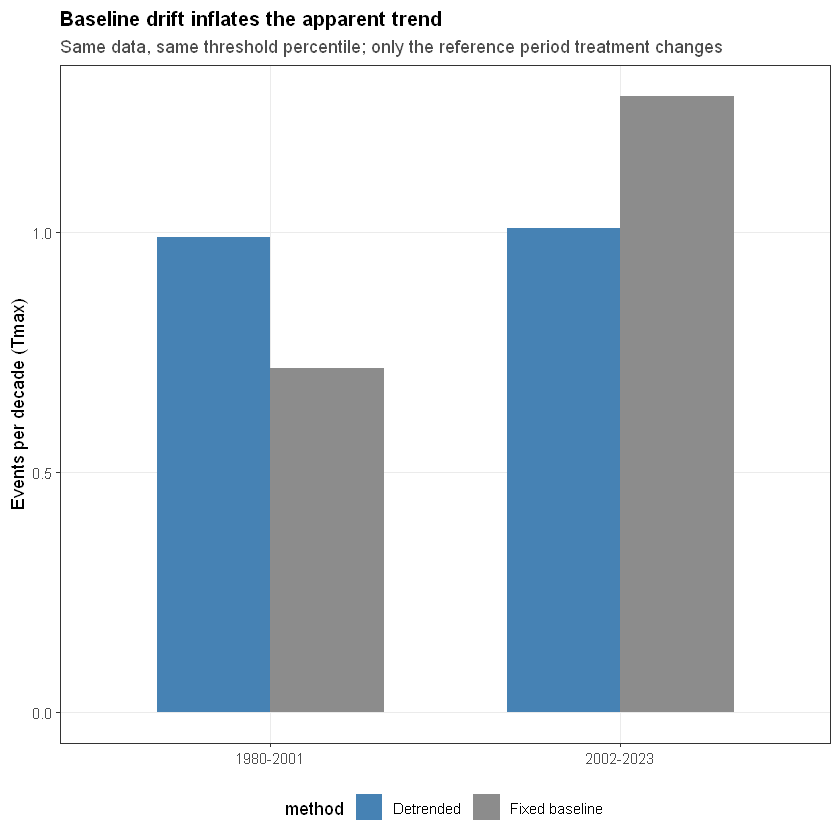

In [7]:
rate_cmp <- data.frame(
  epoch  = rep(c("1980-2001", "2002-2023"), 2),
  method = rep(c("Fixed baseline", "Detrended"), each = 2),
  rate   = c(rate_fixed["Tmax", ], prop.table(tab_dt, 1)["Tmax", ] * 2)
)

p_ns <- ggplot(rate_cmp, aes(epoch, rate, fill = method)) +
  geom_col(position = "dodge", width = 0.65) +
  scale_fill_manual(values = c("Fixed baseline" = "grey55",
                               "Detrended" = "steelblue")) +
  labs(x = NULL, y = "Events per decade (Tmax)",
       title = "Baseline drift inflates the apparent trend",
       subtitle = "Same data, same threshold percentile; only the reference period treatment changes") +
  theme_paper()

save_fig(p_ns, "S14_ns_baseline", 6.2, 4.2)
p_ns

### 3.4 方案 B：时变阈值（滚动基准）

另一种做法是让阈值随时间移动（例如每 30 年滚动一次）。
数学上它和去趋势等价，但**实现更贵**（每年都要重算一次 365 天的分位数），
而且有一个致命副作用：**它会主动抹掉原本想研究的趋势**。

> 📌 **选哪个？取决于问题：**
> - 问「相对于历史常态，现在是否更异常」→ **固定基准期**（本研究的主分析）
> - 问「事件本身的物理强度是否在增加」→ **去趋势 + 报告趋势大小**
> - 问「未来风险如何变化」→ **非平稳极值模型**（GEV/GP 带时间协变量，超出本手册范围）
>
> ⚠️ 两种口径**不能混着解释**。论文里必须明确写你用的是哪一种，以及为什么。

---

## 4. 暖年分层：ENSO 的代理分析

ENSO 是马来西亚热浪最常被引用的年际驱动因子。标准做法是用 ONI 指数分层。

**本手册的模拟数据没有 ONI**，所以这里用一个**数据驱动的代理**：
区域年平均 Tmax 的去趋势异常，按三分位分成冷 / 中性 / 暖年。
真实数据到位后，**把 `anom` 换成 ONI 即可**，其余代码不变。

In [8]:
reg <- aggregate(tmax ~ yr, data = d, FUN = mean, na.rm = TRUE)
reg$anom <- resid(lm(tmax ~ yr, reg))
brk <- quantile(reg$anom, c(1/3, 2/3))
reg$phase <- cut(reg$anom, c(-Inf, brk, Inf),
                 labels = c("cool", "neutral", "warm"))

print(table(reg$phase))
cat("三分位切点:", paste(round(brk, 3), collapse = " / "), "\n")


   cool neutral    warm 
     15      14      15 


三分位切点: -0.01 / 0.015 


In [9]:
evx <- ev0[ev0$defn == "Tmax", ]
cnt <- as.data.frame(table(yr = evx$start_year), responseName = "n")
cnt$yr <- as.integer(as.character(cnt$yr))
cnt  <- merge(reg[, c("yr", "anom", "phase")], cnt, by = "yr", all.x = TRUE)
cnt$n[is.na(cnt$n)] <- 0

cat("\n各相位的年均事件数（全站合计）:\n")
print(round(tapply(cnt$n, cnt$phase, mean), 2))


各相位的年均事件数（全站合计）:


   cool neutral    warm 
  22.40   21.71   27.33 


In [10]:
# 泊松回归：事件数 ~ 区域异常。先看离散度，再决定要不要 quasi-Poisson
g_pois <- glm(n ~ anom, family = poisson, data = cnt)
disp   <- sum(resid(g_pois, type = "pearson")^2) / df.residual(g_pois)
cat(sprintf("Poisson 离散度 = %.2f （>1.5 说明过度离散）\n", disp))
cat(sprintf("Poisson 下 anom 的 p 值：%.4f\n",
            summary(g_pois)$coefficients["anom", "Pr(>|z|)"]))

g <- glm(n ~ anom, family = quasipoisson, data = cnt)
print(round(summary(g)$coefficients, 3))

Poisson 离散度 = 3.18 （>1.5 说明过度离散）


Poisson 下 anom 的 p 值：0.0371


            Estimate Std. Error t value Pr(>|t|)
(Intercept)    3.170      0.055  57.443    0.000
anom           1.611      1.379   1.168    0.249


> 🚨 **同一份数据，两个 p 值差了七倍：Poisson 给 0.037，quasi-Poisson 给 0.249。**
> 差别全部来自离散度 3.2 —— 年际事件数的方差是均值的 3 倍多。
> 若图省事用 Poisson，就会把一个**不可分辨的信号**写成「显著」。
> **这就是为什么 §8 检查清单里「是否检查离散度」必须单独列一行。**


区域异常 +1 degC -> 事件数 x5.01  (95% CI 0.34 - 74.77)


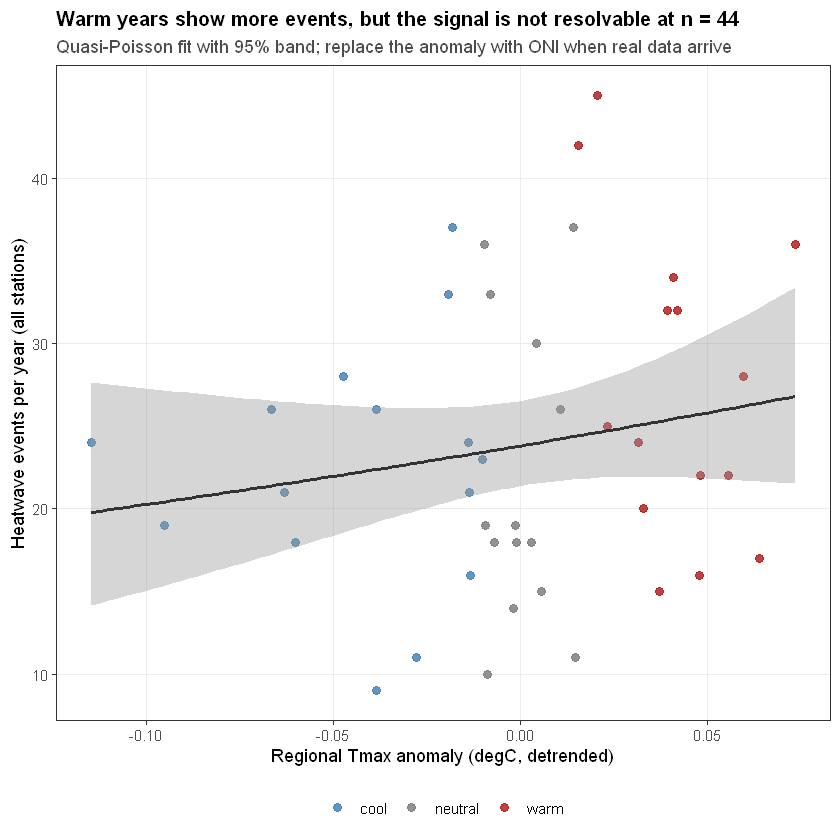

In [11]:
b  <- coef(g)["anom"]
ci <- confint.default(g)["anom", ]
cat(sprintf("\n区域异常 +1 degC -> 事件数 x%.2f  (95%% CI %.2f - %.2f)\n",
            exp(b), exp(ci[1]), exp(ci[2])))

p_enso <- ggplot(cnt, aes(anom, n)) +
  geom_point(aes(colour = phase), size = 2.2, alpha = 0.85) +
  geom_smooth(method = "glm", method.args = list(family = quasipoisson),
              formula = y ~ x, se = TRUE, colour = "grey20") +
  scale_colour_manual(values = c(cool = "steelblue", neutral = "grey50",
                                 warm = "firebrick"), name = NULL) +
  labs(x = "Regional Tmax anomaly (degC, detrended)",
       y = "Heatwave events per year (all stations)",
       title = "Warm years show more events, but the signal is not resolvable at n = 44",
       subtitle = "Quasi-Poisson fit with 95% band; replace the anomaly with ONI when real data arrive") +
  theme_paper()

save_fig(p_enso, "S14_enso_proxy", 6.5, 4.2)
p_enso

> 🔍 **点估计的方向是对的，但精度不够。**
> 暖年 27.3 件/年、冷年 22.4 件/年，看起来差 22%；可是每个相位的年际标准差就有 7–9，
> 而且只有 14–15 个年值。quasi-Poisson 给出的区间宽到几乎横跨整个横轴。
>
> ✅ **推荐写法**
> 「Events were more frequent in warm years (27.3 vs 22.4 per year), but with only 44 annual
> observations and substantial year-to-year variance (dispersion 3.2), the quasi-Poisson
> estimate is too imprecise to be distinguished from zero (rate ratio per °C = 5.0, 95% CI
> 0.34–74.8). We therefore treat this as a **hypothesis-generating** result and reserve the
> ENSO analysis for the full record with an explicit ONI stratification.」
>
> ❌ **不要写**「暖年热浪显著增多」—— Poisson 会给你 p = 0.037，但那个 p 是过度离散造出来的。

> 📌 **方法章必须写清楚这是一个代理**：
> 「In the absence of an ENSO index for the synthetic validation dataset, annual regional
> temperature anomalies are used as a proxy for the large-scale forcing. In the final analysis
> this variable is replaced by the NOAA Oceanic Niño Index (ONI), and the stratification is
> repeated with the standard ±0.5 °C threshold definition.」
>
> 这样写既诚实，又说明你知道正确做法是什么 —— 审稿人看的是后者。

---

## 5. 参数敏感性表

把 §1 清单里影响最大的几个选择真正跑一遍。

In [12]:
run_variant <- function(prob = CFG$prob_default, halfwin = CFG$halfwin,
                        min_len = CFG$min_len, max_gap = CFG$max_gap,
                        base_years = CFG$base_years, data = d, suffix = "") {
  cfg <- CFG
  cfg$halfwin <- halfwin; cfg$min_len <- min_len
  cfg$max_gap <- max_gap; cfg$base_years <- base_years

  do.call(rbind, lapply(split(data, data$station), function(s)
    do.call(rbind, lapply(DEFS, function(dn) {
      x <- extract_events(s, paste0(VAR_OF[[dn]], suffix), defn = dn,
                          prob = prob, cfg = cfg)
      if (is.null(x)) NULL else x
    }))))
}

# 每个变体算同一组关键指标
variant_metrics <- function(ev) {
  e  <- ev[ev$defn == "Tmax" & ev$station == "Kuantan", ]
  st <- panel[panel$station == "Kuantan", ]
  es <- st$state[match(e$start_date, st$date)]

  a  <- sum(es == "dry", na.rm = TRUE); b <- sum(es == "wet", na.rm = TRUE)
  nd <- sum(st$state == "dry", na.rm = TRUE)
  nw <- sum(st$state == "wet", na.rm = TRUE)

  sev <- tapply(ev$severity, list(ev$station, ev$defn), sum) / n_years
  rdi_v <- rdi(rank(-sev[, "Tmax"], ties.method = "average"),
               rank(-sev[, "Twmax"], ties.method = "average"))

  c(n_events = nrow(ev),
    med_dur  = median(ev$duration),
    mean_int = mean(ev$intensity),
    tau      = cor(e$duration, e$intensity, method = "kendall"),
    RR       = (a / nd) / (b / nw),
    RDI      = rdi_v)
}

In [13]:
variants <- list(
  "Baseline"            = function() ev0,
  "Half-window ±14 d"   = function() run_variant(halfwin = 14),
  "90th -> 95th pct"    = function() run_variant(prob = 0.95),
  "min 5 d, no merging" = function() run_variant(min_len = 5, max_gap = 0),
  "Base 1991-2020"      = function() run_variant(base_years = 1991:2020),
  "Detrended threshold" = function() run_variant(data = d_dt, suffix = "_dt")
)

sens <- do.call(rbind, lapply(names(variants), function(nm) {
  cat("运行:", nm, "... ")
  t0 <- Sys.time()
  ev <- variants[[nm]]()
  cat(nrow(ev), "事件, ",
      round(as.numeric(difftime(Sys.time(), t0, units = "secs")), 1), "s\n")
  data.frame(variant = nm, t(round(variant_metrics(ev), 3)))
}))
print(sens, row.names = FALSE)

运行: Baseline ... 2485 事件,  0 s
运行: Half-window ±14 d ... 2510 事件,  15 s
运行: 90th -> 95th pct ... 874 事件,  13.6 s
运行: min 5 d, no merging ... 705 事件,  14.2 s
运行: Base 1991-2020 ... 2110 事件,  22.4 s
运行: Detrended threshold ... 2411 事件,  28.2 s


             variant n_events med_dur mean_int   tau    RR  RDI
            Baseline     2485       4    1.793 0.295 4.166 0.08
   Half-window ±14 d     2510       4    1.805 0.344 4.806 0.16
    90th -> 95th pct      874       3    1.548 0.239 7.290 0.28
 min 5 d, no merging      705       5    2.130 0.243 3.605 0.36
      Base 1991-2020     2110       4    1.765 0.259 4.206 0.24
 Detrended threshold     2411       4    1.746 0.218 4.963 0.20


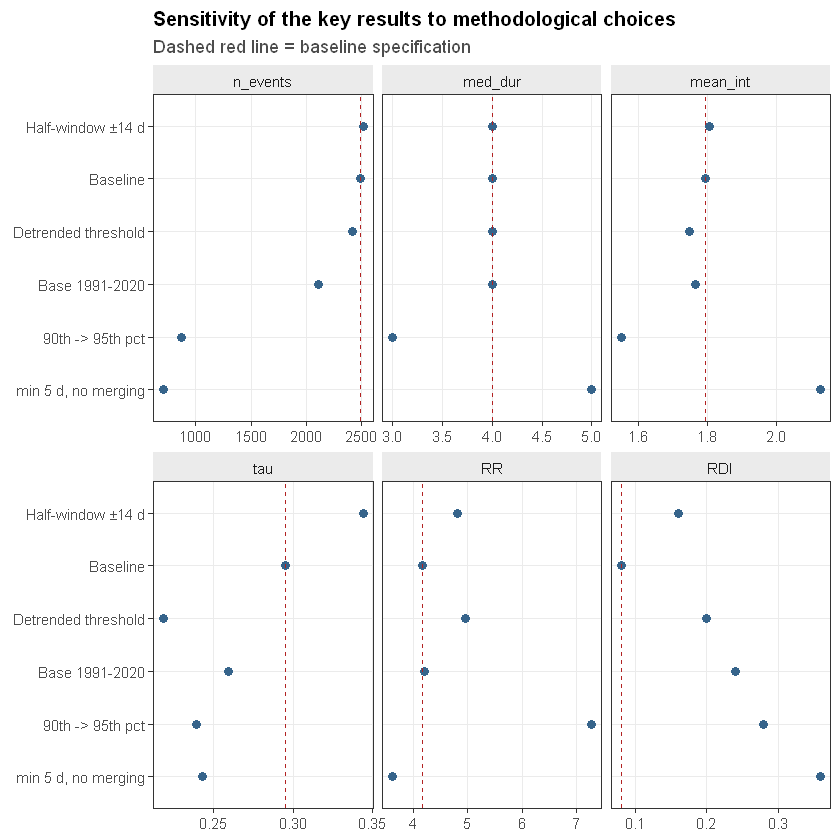

In [14]:
# 长表 + 分面点图：一眼看出哪个指标对哪个设定敏感
long <- tidyr::pivot_longer(sens, -variant, names_to = "metric", values_to = "value")
long$metric <- factor(long$metric, levels = c("n_events", "med_dur", "mean_int",
                                              "tau", "RR", "RDI"))

p_sens <- ggplot(long, aes(value, reorder(variant, value))) +
  geom_point(size = 2.2, colour = "steelblue4") +
  geom_vline(data = subset(long, variant == "Baseline"),
             aes(xintercept = value), linetype = "dashed", colour = "firebrick") +
  facet_wrap(~metric, scales = "free_x", nrow = 2) +
  labs(x = NULL, y = NULL,
       title = "Sensitivity of the key results to methodological choices",
       subtitle = "Dashed red line = baseline specification") +
  theme_paper()

save_fig(p_sens, "S14_sensitivity", 9, 5)
p_sens

---

## 6. 稳健性结论：怎么写，不怎么写

In [15]:
# 把每个指标在各变体间的相对跨度算出来
spread <- sapply(sens[, -1], function(x) (max(x) - min(x)) / abs(mean(x)))
cat("各指标在变体间的相对跨度:\n")
print(round(sort(spread, decreasing = TRUE), 3))

各指标在变体间的相对跨度:


     RDI n_events       RR  med_dur      tau mean_int 
   1.273    0.976    0.761    0.500    0.473    0.324 


> 🔍 **读法**：看每个分面里点的**横向散布宽度**相对于基线值。
> - 散布窄 → 结论对这个设定稳健
> - 散布宽 → 必须在论文里单独讨论
>
> **本例的结果值得逐项看：**
>
> | 指标 | 范围（6 个变体） | 相对跨度 | 判断 |
> |---|---|---|---|
> | `mean_int` | 1.55 – 2.13 | 0.32 | 中等 |
> | `tau` | 0.218 – 0.344 | 0.47 | 中等 |
> | `med_dur` | 3 – 5 | 0.50 | 中等（部分由构造决定） |
> | `RR` | 3.61 – 7.29 | 0.76 | 大 |
> | `n_events` | 705 – 2510 | 0.98 | 极大 |
> | `RDI` | 0.08 – 0.36 | 1.27 | 极大 |
>
> 🚨 **这里有一个必须承认的事实：没有一个指标是真正「稳健」的。**
> 六个变体已经足以让 RDI 从 0.08 涨到 0.36 —— 也就是说
> **S13 里「年均 severity 排序高度一致」这个结论，本身就依赖于阈值设定。**
> 这不是要你删掉 S13，而是要你在 Discussion 里写清楚它的条件性。
>
> ✅ **真正稳的是「方向」，不是「大小」：**
> RR 在所有变体下都 > 1（3.6–7.3）；τ 在所有变体下都 > 0（0.22–0.34）；
> RDI 在所有变体下都远低于零分布均值 0.66。
> **结论应该建立在这些符号和数量级上，而不是「τ = 0.295」这种精确到小数点后三位的说法。**

> 📌 **判定规则（可以直接写进 Discussion）：**
>
> | 相对跨度 | 结论强度 |
> |---|---|
> | < 0.2 | 稳健，可作为主结论 |
> | 0.2 – 0.5 | 需报告范围，措辞用 "approximately" |
> | > 0.5 | 只能在特定设定下成立，必须写明前提 |
>
> 按这张表，本例**只有 `mean_int` 落在「需报告范围」档**，其余全部需要写明前提。
> 一份诚实的敏感性分析，结论往往就是这样「没那么漂亮」的。

> ✅ **推荐写法**
> 「The sign and order of magnitude of every core result are stable across all six
> specifications: relative risk exceeds unity in every variant (3.6–7.3), Kendall's τ remains
> positive (0.22–0.34), and the definition-disagreement index stays well below the value
> expected under independent rankings (0.08–0.36 vs a null mean of 0.66). The magnitudes,
> however, are specification-dependent: event counts vary by a factor of 3.6 and RDI by a
> factor of 4.5 across equally defensible choices. We therefore report effect directions and
> ranges rather than point estimates as our primary evidence, and we treat the 90th-percentile,
> ±7-day, 3-day-minimum specification as the reference rather than as the definitive one.」

> ❌ **不要写**
> 「结果对参数选择不敏感。」—— 本例的敏感性表直接否定了这句话。
> 更糟的是：审稿人只要换一个阈值重跑，就能拆穿它。

---

## 7. 写作模板（可直接改写）

### 7.1 Results —— 描述统计段

> 「Across the 10 stations and three heat definitions, the 90th-percentile calendar-day
> threshold yields **N** events over the 44-year record (Tmax: n = **x**; Tmin: n = **y**;
> Twmax: n = **z**). Median event duration is **d** days (IQR **i1–i2**) and mean peak
> exceedance is **m** °C. Events cluster in February–April and June–August, with **p**% of
> onsets occurring under antecedent conditions classified as dry (ARP < 30th percentile),
> against a base rate of **q**%.」

### 7.2 Results —— 核心发现段

> 「Events are **RR** times more likely to begin on dry-antecedent days than on wet-antecedent
> days (95% CI **lo–hi**; day-of-year permutation p = **p**; BH-FDR adjusted across 30
> station–definition cells). The duration–intensity dependence is positive and moderate
> (Kendall's τ = **t**, n = **n**), and **is not** detectably modified by antecedent state
> (pooled Δτ = **dt**, permutation p = **dp**; detectable effect |Δτ| ≳ **dmin**).」

### 7.3 Discussion —— 机制段

> 「The contrast between a strong onset signal and a null dependence signal is mechanistically
> coherent. Antecedent soil moisture controls whether the surface energy balance can push
> near-surface temperature across the local threshold — an **occurrence** question sensitive to
> land–atmosphere coupling. Once an event is underway, its duration and peak are governed by
> synoptic-scale circulation (monsoon surges, MJO phases), which is largely independent of the
> pre-event moisture state. The data therefore support a two-stage picture: antecedent moisture
> gates **initiation**, while large-scale dynamics set **structure**.」

### 7.4 Limitations —— 必须自己先说

> 「Four limitations should be noted. First, the analysis treats the threshold as stationary;
> a fixed 1985–2014 baseline produces an apparent 79% increase in event counts between the
> first and second halves of the record that disappears entirely under a detrended threshold,
> indicating that frequency trends should not be inferred without a non-stationary model.
> Second, with 15–60 events per state-stratified cell, tail-dependence coefficients are not
> identifiable, and our design has power only for |Δτ| ≳ 0.36. Third, return levels beyond the
> empirical range (T ≥ 25 years) rely on the parametric marginal form. Fourth, the six
> candidate copulas are statistically indistinguishable (ΔAIC < 2) yet differ in λ_U from 0 to
> 0.33; we therefore report ensemble ranges rather than a single model's tail dependence.」

> 🚨 **Limitations 段的作用不是自谦，是抢先回答审稿人的问题。**
> 上面每一句都对应一个具体数字，而不是泛泛的「样本有限」。

---

## 8. 投稿前检查清单

| 类别 | 检查项 |
|---|---|
| **可复现** | 代码、数据、随机种子是否公开或可申请？ |
| | 每个随机过程（PIT、bootstrap、置换）是否固定了 seed？ |
| | 包版本是否记录（`sessionInfo()`）？ |
| **定义** | 阈值、百分位方法（type=8）、基准期是否写明？ |
| | 事件的最短持续、合并规则是否写明？ |
| | 强度的定义是峰值超出还是平均超出？ |
| **统计** | 是否报告了效应量 + 置信区间，而不只是 p？ |
| | 多重比较是否校正（BH-FDR）？ |
| | 置换检验是否保持了时间结构（按日序置换）？ |
| | 是否报告了检验力 / 可检出的最小效应？ |
| **copula** | 是否说明 IFM 两步法而非联合 ML？ |
| | 是否报告了 `tau_fit` 与样本 τ 的对照？ |
| | ΔAIC < 2 的模型是否都进了结果？ |
| | 尾部依赖是否标注「模型属性」？ |
| **重现期** | 事件率的分母是否是记录长度？ |
| | AND / OR / Kendall 是否说明选哪个及理由？ |
| | 超出经验范围的重现期是否标注为外推？ |
| **稳健性** | 阈值、窗口、持续时间是否至少各做一次敏感性？ |
| | 非平稳性是否检查（固定 vs 去趋势）？ |
| **诚实性** | 零结果是否写成「未检出」而非「不存在」？ |
| | 是否说明了本设计**不能**回答的问题？ |

---

## 9. 常见错误

| 错误 | 后果 |
|---|---|
| 用固定基准期解释事件数趋势 | 把基准期漂移误读成气候信号 |
| 敏感性分析只跑「看起来会通过」的设定 | 选择性报告，等同 p-hacking |
| 用 Poisson 而不检查离散度 | 标准误被低估 2–3 倍，假阳性 |
| 把代理变量（温度异常）当 ENSO 写 | 概念错误，审稿人一眼识破 |
| Limitations 写成套话 | 失去抢先解释的机会 |
| 只报「稳健」不报具体范围 | 读者无法判断稳健到什么程度 |
| 敏感性分析改变了两个参数却不拆开 | 无法归因是哪一项造成的差异 |

---

## 10. 自检问题

<details>
<summary>Q1：为什么固定基准期会产生「事件变多」的假象？</summary>

阈值由 1985–2014 的数据定出。如果之后气候变暖，同样的物理阈值会被更容易越过，事件数自然上升。这不是「热浪变频繁」，而是「尺子没跟着气候走」。去趋势后两段时期的事件率几乎相同（0.99 vs 1.01），证明增长几乎全部来自基准期漂移。

</details>

<details>
<summary>Q2：去趋势阈值有没有缺点？</summary>

有。它会**主动移除**你想研究的趋势。如果你的科学问题是「热浪是否在增加」，去趋势就是循环论证。正确做法是：主分析用固定基准期 + 明确的非平稳性讨论，或用带时间协变量的非平稳极值模型，而把去趋势作为**诊断**而非主结果。

</details>

<details>
<summary>Q3：为什么 `n_events` 对参数极度敏感，而 τ 不敏感？</summary>

因为事件数是**计数**，直接由阈值高低决定；而 τ 是**秩相关**，只关心「长事件是否倾向于是强事件」这个相对关系。改变阈值会同时删掉一批事件，但只要删掉的方式不系统性地偏向某一端，秩结构就基本不变。这就是为什么**结构量比计数更适合作为核心结论**。

</details>

<details>
<summary>Q4：敏感性分析要跑多少个变体才够？</summary>

没有标准答案，但原则是：**每个「合理的替代选择」至少一个**，并且优先跑那些你预期影响最大的。审稿人通常关心阈值（90 vs 95）、窗口（±7 vs ±14）和最短持续（3 vs 5）。跑 4–8 个变体、报告完整的指标表，比跑 20 个只报「都稳健」更有说服力。

</details>

<details>
<summary>Q5：如果敏感性分析发现核心结论翻转了，怎么办？</summary>

这正是敏感性分析的价值 —— 早发现总比审稿人发现好。三种处理：(1) 如果某个设定更符合你的科学问题，说明理由并以其为主分析；(2) 如果两个设定都合理，把结论写成条件式（"under a 95th-percentile threshold, X holds; under the 90th, it does not"）；(3) 如果差异源于样本量而非机制，明确报告检验力不足。

</details>

---

## 11. 14 天路线回顾

| Day | 主题 | 对应论文 |
|---|---|---|
| S01 | 数据审计与质控 | 3.1 Data |
| S02 | 日历日滑动窗阈值 | 3.2 Thresholds |
| S03 | 游程理论与事件提取 | 3.3 Event definition |
| S04 | 三套定义的设计逻辑 | 3.4 Definitions |
| S05 | 事件目录与样本量现实 | 4.1 Catalogue |
| S06 | 前期降雨状态（ARP/CDD） | 3.5 Antecedent |
| S07 | RO2：相对风险 + 置换检验 | 3.6 + 4.2 |
| S08 | Copula 框架与 τ 的不变性 | 3.7.1 |
| S09 | 边缘分布与 PIT 的三种版本 | 3.7.2 |
| S10 | copula 拟合、AIC 与尾部依赖 | 3.7.3 + 4.3 |
| S11 | RO3：条件依赖与零结果 | 3.7.4 |
| S12 | 联合重现期三种定义 | 3.8 + 4.4 |
| S13 | 定义敏感性（RDI） | 3.9 + 4.5 |
| S14 | 稳健性、非平稳性与写作 | 3.10 + 4.6 + 5 |

> 🎯 **最后一句**：这 14 天教的不是 14 个工具，而是**一种工作方式** ——
> 每一个选择都被意识到、被记录、被检验。
> 真正让一篇本科论文达到 SCI 水准的，不是用了 copula，
> 而是**知道 copula 什么时候不该用，并且写得出来**。